# 4 · 分析比較:潛空間的群聚、解釋性、連續性

換到**體制形態層**(12 城 × 5 情形 = 60 樣本 × 9 形態特徵),問三件事:

1. **群聚**:哪個潛空間把資料分得最清楚?無監督 KMeans 能不能復原**手動 regimes**?
2. **解釋性**:軸/載荷是什麼?誰在成簇(體制 vs 家族)?
3. **連續性**:潛空間可不可讀、可不可插值。

> 用 `regime_latent` 子套件(有別於 NB1-3 的建築層)。

## 環境 + 語料

In [1]:
import sys, os
from pathlib import Path
_here = Path(os.getcwd()).resolve()
_r07 = next((p for p in [_here, *_here.parents] if (p / 'nn').exists()), _here)
if str(_r07) not in sys.path: sys.path.insert(0, str(_r07))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import regime_latent as rl       # 體制形態層 + 中文字型
print('07 根:', _r07)
from regime_latent import encoders as L

07 根: C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban


In [2]:
if not rl._paths.CSV.exists():
    rl.corpus.build()
df = pd.read_csv(rl._paths.CSV)
X = df[L.FEATURES].values.astype(float)
std = L.Standardizer().fit(X); Xz = std.transform(X)
print('語料', Xz.shape); print(df.groupby('regime').size().to_string())

語料 (60, 9)
regime
baseline               12
developer_led          12
resident_self_build    12
shared                 12
state_led              12


## 4.1 降維方法差異(PCA / t-SNE / Isomap)
同語料三投影,看群聚結構。

[fig] 01_method_compare.png


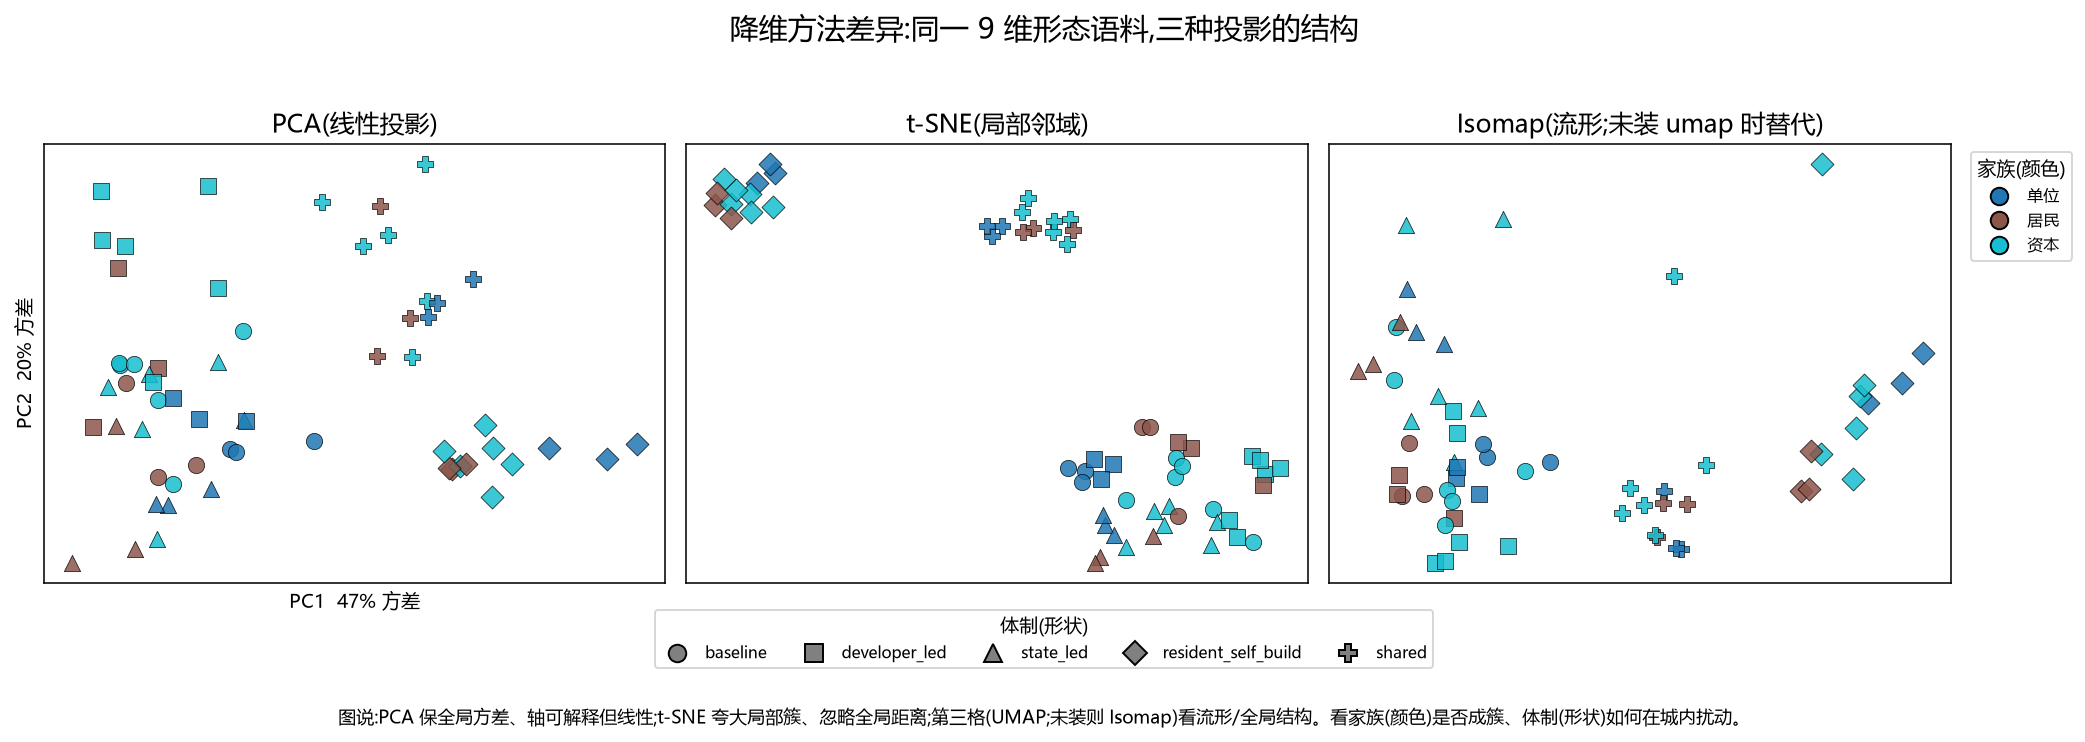

In [3]:
rl.analysis.fig_method_compare(df, Xz)
display(Image(str(rl._paths.FIGS / '01_method_compare.png')))

## 4.2 群聚 vs 手動 regimes(KMeans)
**不給標籤**,KMeans 只看形態能否分出 5 群、對不對得上手動 regime(ARI 高=對得上)。
→ 這就是 NN/資料驅動**有別於手動設定 regimes** 的能力:客觀檢驗、甚至發現新族群。

[fig] 08_cluster_vs_regime.png

=== 聚类 vs regime ===
 space      ARI  silhouette
 原始9维 0.704243    0.320571
PCA-2 0.545543    0.487977
 AE-2 0.337419    0.552943
VAE-2 0.559661    0.581414
最佳空间: 原始9维


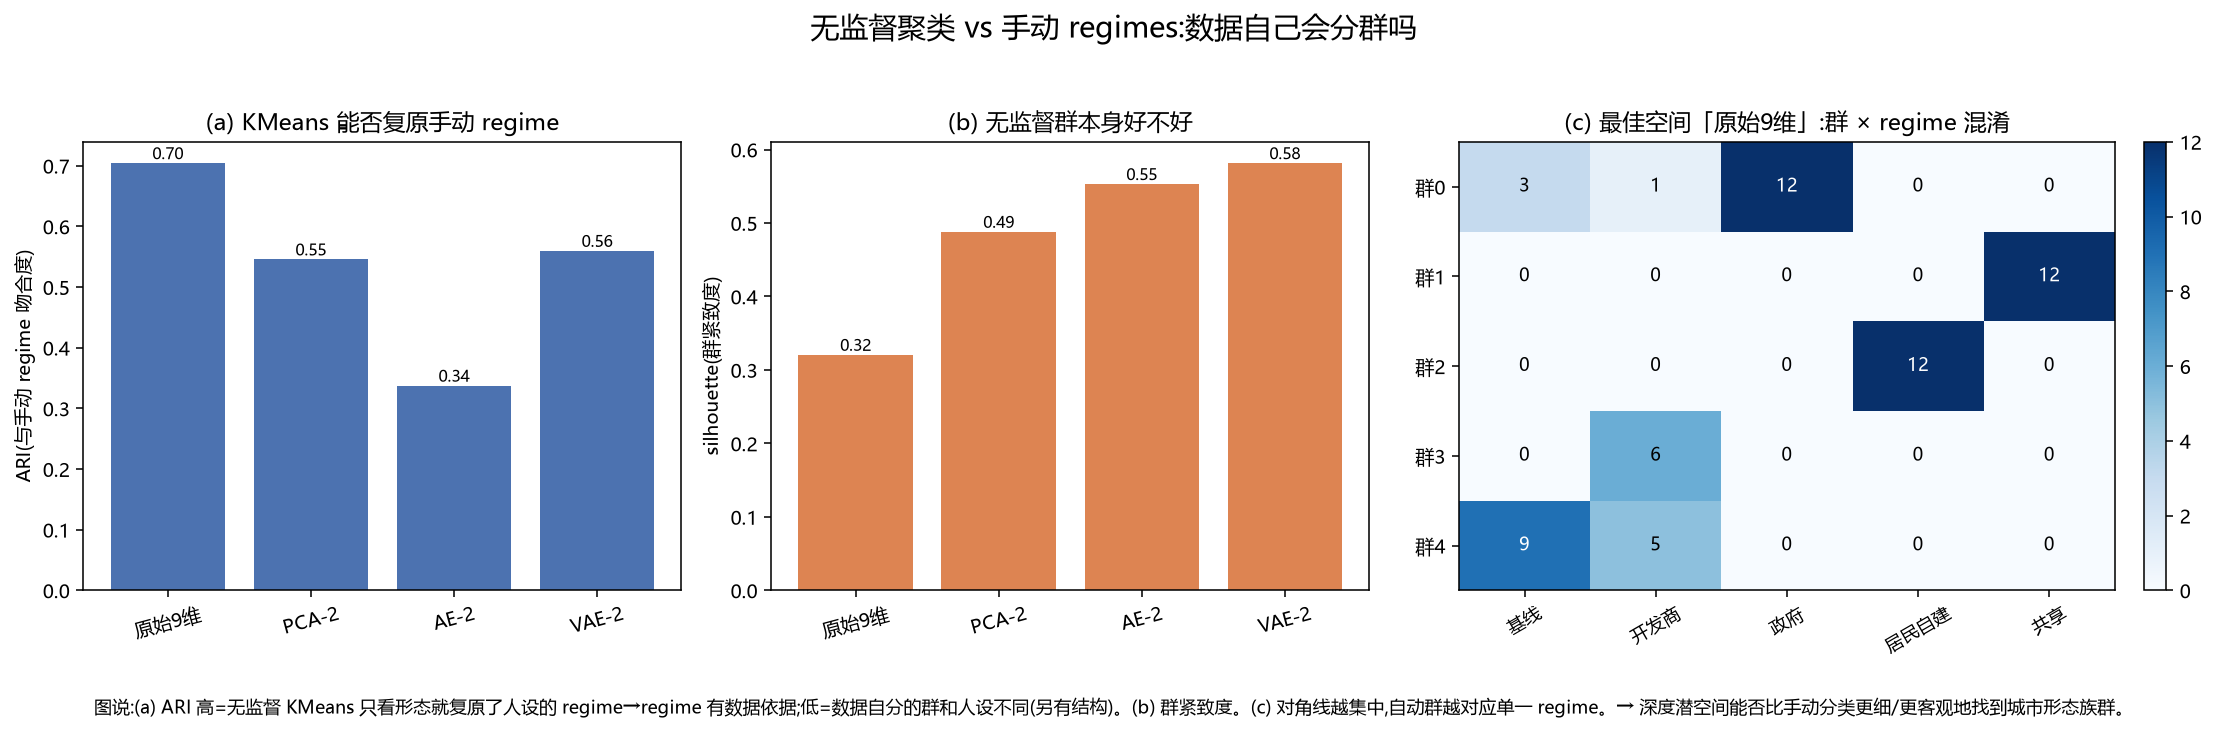

,space,ARI,silhouette
0,原始9维,0.704243,0.320571
1,PCA-2,0.545543,0.487977
2,AE-2,0.337419,0.552943
3,VAE-2,0.559661,0.581414


In [4]:
res = rl.cluster.fig_cluster_vs_regime(df, Xz, k=5)
display(Image(str(rl._paths.FIGS / '08_cluster_vs_regime.png')))
res

## 4.3 解釋性:誰在成簇 + 軸的含義
silhouette(體制 vs 家族)+ PCA 載荷。

[fig] 04_cluster_interpret.png

=== silhouette ===
  space       按家族      按体制
  原始9维  0.037500 0.243968
   PCA -0.042284 0.236598
 t-SNE -0.029916 0.417653
Isomap -0.050955 0.273843


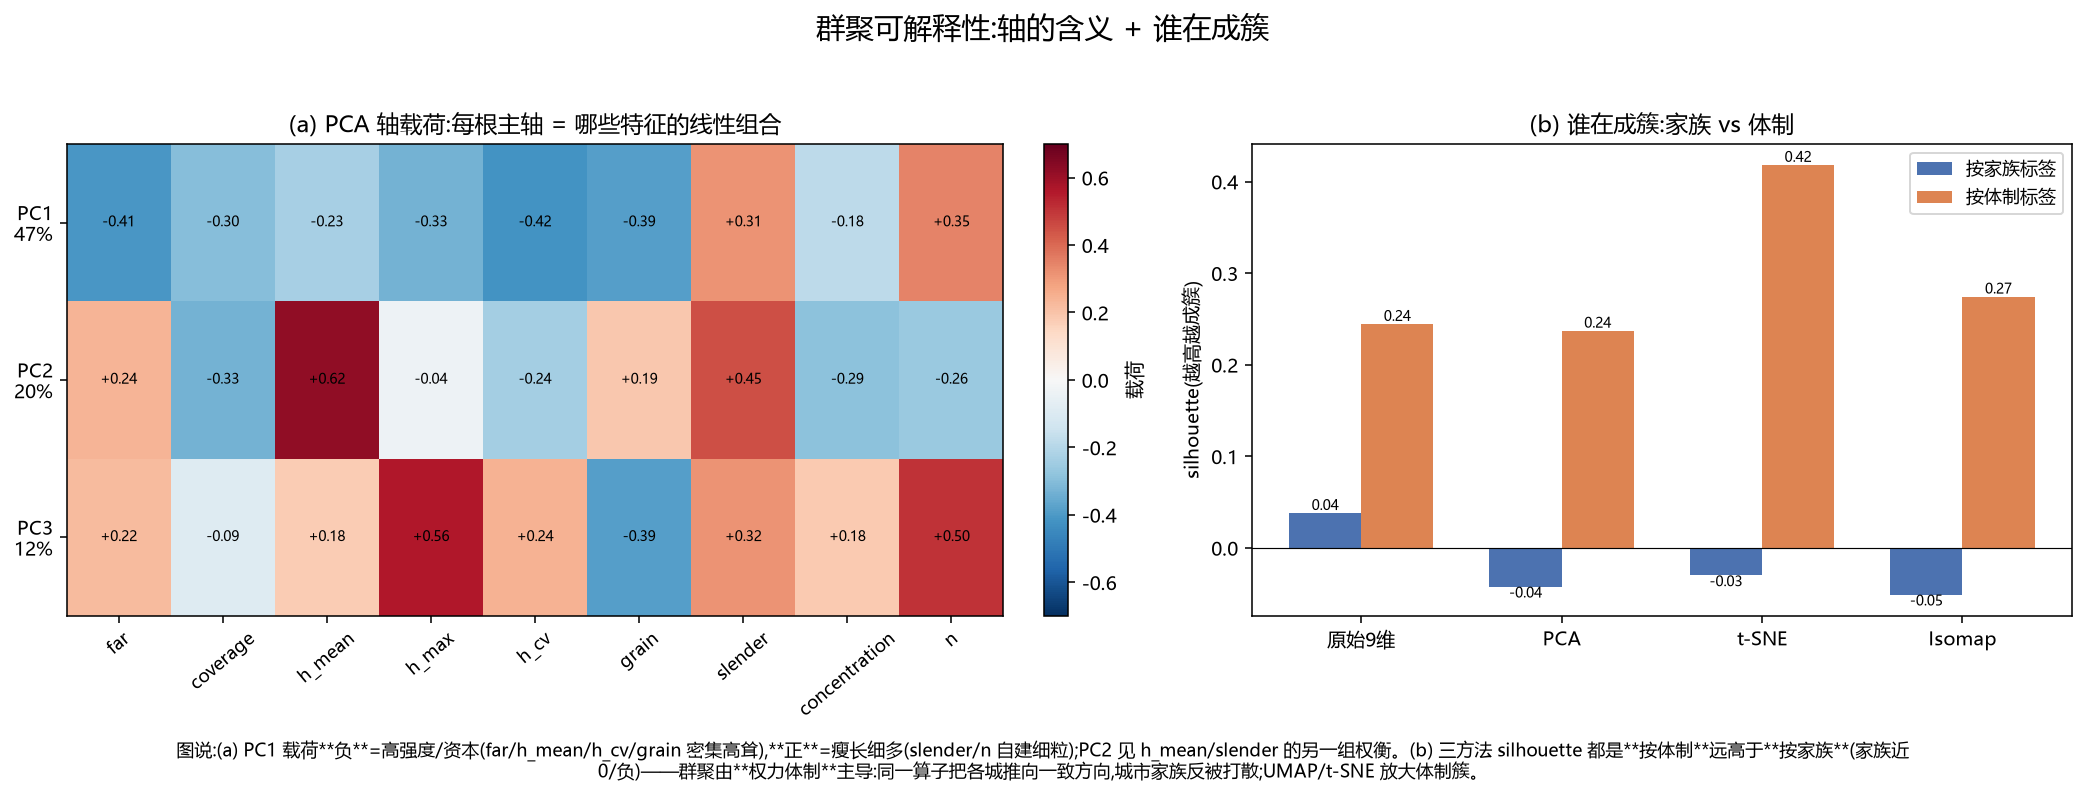

In [5]:
pca = rl.interpret.fig_cluster_interpret(df, Xz)
display(Image(str(rl._paths.FIGS / '04_cluster_interpret.png')))

## 4.4 連續性:潛空間能不能插值
兩真實樣本間插值,中點離流形越近=潛空間越連續可讀(NB5 生成會用到)。

In [6]:
pca_ref, gen, gm = rl.generate.run(df, Xz, std)
print('插值中點→流形距離(σ,越低越連續):')
for gname in ('PCA','AE','VAE'):
    print(f"  {gname:4s} {gm[gname]['interp']:.3f}")

插值中點→流形距離(σ,越低越連續):
  PCA  1.150
  AE   1.426
  VAE  1.042


## 小結
- **群聚**:KMeans ARI 高 → 手動 regimes 有資料依據;深度潛空間(VAE)群更緊(silhouette 高)。
- **解釋性**:群聚由**體制**主導、非城市家族;PCA 軸=強度/資本 vs 細粒自建。
- **連續性**:VAE 潛空間插值最平滑 → 最適合生成(NB5)。